# Librerias, semillas, datos y loaders

In [ ]:
# Librerías
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import json

from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Semillas y dispositivo
SEED = 42

def set_seed(seed):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# print('Dispositivo:', device)

In [ ]:
# Transformación: ToTensor lleva los píxeles a [0, 1] y luego se reescalan a [-1, 1]
transform = transforms.Compose([
  transforms.ToTensor(),
  transforms.Normalize((0.5,), (0.5,)),   # (x - 0.5) / 0.5
])

# Train, validation y test
train_full = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# Se parte el train oficial (60.000) en 50.000 train y 10.000 validation
generator = torch.Generator().manual_seed(SEED)
train_set, valid_set = random_split(train_full, [50000, 10000], generator=generator)

# Nombres de las clases
class_names = {0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'}

# DataLoaders (mini-batches de 100)
BATCH_SIZE = 100
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

# Para evaluar train sin mezclar el orden
train_eval_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=False)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.3MB/s]


# Modelo

In [ ]:
# Red MLP: 784 -> 128 -> 64 -> 10
DROPOUT_P = 0.2
class MLP(nn.Module):
  def __init__(self, dropout_p=DROPOUT_P):
    super().__init__()
    self.net = nn.Sequential(
      nn.Flatten(),  # (B, 1, 28, 28) -> (B, 784)
      nn.Linear(784, 128), nn.ReLU(), nn.Dropout(dropout_p),
      nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout_p),
      nn.Linear(64, 10),  # 10 logits, sin Softmax
    )

  def forward(self, x):
    return self.net(x)

# Función de pérdida: recibe logits y etiquetas enteras
criterion = nn.CrossEntropyLoss()

# Optimizador
SGD_LR = 0.01
ADAM_LR = 0.001
def make_optimizer(name, model):
  if name == 'SGD':
    return torch.optim.SGD(model.parameters(), lr=SGD_LR)
  elif name == 'Adam':
    return torch.optim.Adam(model.parameters(), lr=ADAM_LR)
  else:
    raise ValueError(f'Optimizador desconocido: {name}')


# Funciones de Entrenamiento y Evaluacion

In [ ]:
# Entrenamiento de una época
def train_one_epoch(model, loader, criterion, optimizer):
  model.train()                          # activa Dropout
  for images, labels in loader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()              # borra gradientes del paso anterior
    logits = model(images)             # forward
    loss = criterion(logits, labels)   # pérdida del mini-batch
    loss.backward()                    # backpropagation
    optimizer.step()                   # actualiza los pesos

# Evaluación sobre un loader completo (no actualiza pesos)
def evaluate(model, loader, criterion):
  model.eval()  # desactiva Dropout
  total_loss, correct, total = 0.0, 0, 0

  with torch.no_grad():  # no calcula gradientes
    for images, labels in loader:
      images, labels = images.to(device), labels.to(device)

      logits = model(images)
      loss = criterion(logits, labels)

      total_loss += loss.item() * images.size(0)   # pérdida ponderada por el tamaño del batch
      correct += (logits.argmax(dim=1) == labels).sum().item()
      total += images.size(0)

  return total_loss / total, correct / total   # loss promedio y accuracy

# Entrena un modelo nuevo y guarda las métricas por época
def run_experiment(optimizer_name, seed, epochs):
  set_seed(seed)
  model = MLP().to(device)
  optimizer = make_optimizer(optimizer_name, model)

  history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

  for epoch in range(1, epochs + 1):
    train_one_epoch(model, train_loader, criterion, optimizer)

    # Métricas al final de la época, con los mismos pesos y el modelo en modo eval
    train_loss, train_acc = evaluate(model, train_eval_loader, criterion)
    val_loss, val_acc = evaluate(model, valid_loader, criterion)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f'{optimizer_name} | época {epoch:2d} | '
          f'train loss {train_loss:.4f} acc {train_acc:.4f} | '
          f'val loss {val_loss:.4f} acc {val_acc:.4f}')

  return model, history

# Ejecución de Train y Validation

In [ ]:
# Correr todas las configuraciones: 2 optimizadores x 3 semillas
EPOCHS = 20
OPTIMIZERS = ['SGD', 'Adam']
SEEDS = [42, 43, 44]  # 42 es la semilla principal

results = {}          # results[(optimizador, semilla)] = (modelo, historial)
for name in OPTIMIZERS:
  for seed in SEEDS:
    print(f'--- {name}, semilla {seed} ---')
    results[(name, seed)] = run_experiment(name, seed, EPOCHS)

--- SGD, semilla 42 ---
SGD | época  1 | train loss 0.7929 acc 0.7381 | val loss 0.8053 acc 0.7279
SGD | época  2 | train loss 0.6295 acc 0.7714 | val loss 0.6471 acc 0.7621
SGD | época  3 | train loss 0.5731 acc 0.7939 | val loss 0.5887 acc 0.7872
SGD | época  4 | train loss 0.5293 acc 0.8081 | val loss 0.5446 acc 0.8050
SGD | época  5 | train loss 0.4976 acc 0.8206 | val loss 0.5120 acc 0.8198
SGD | época  6 | train loss 0.4760 acc 0.8273 | val loss 0.4918 acc 0.8248
SGD | época  7 | train loss 0.4601 acc 0.8333 | val loss 0.4786 acc 0.8288
SGD | época  8 | train loss 0.4457 acc 0.8387 | val loss 0.4640 acc 0.8333
SGD | época  9 | train loss 0.4317 acc 0.8439 | val loss 0.4477 acc 0.8394
SGD | época 10 | train loss 0.4202 acc 0.8473 | val loss 0.4393 acc 0.8420
SGD | época 11 | train loss 0.4121 acc 0.8491 | val loss 0.4304 acc 0.8434
SGD | época 12 | train loss 0.4037 acc 0.8534 | val loss 0.4231 acc 0.8474
SGD | época 13 | train loss 0.3943 acc 0.8576 | val loss 0.4144 acc 0.8510
S

In [ ]:
# Resultado de cada corrida, al final de la última época
LRS = {'SGD': SGD_LR, 'Adam': ADAM_LR}

print(f"{'Optim.':8s}{'lr':>8s}{'semilla':>9s}{'val loss':>11s}{'val acc':>10s}")
for name in OPTIMIZERS:
  for seed in SEEDS:
    h = results[(name, seed)][1]
    print(f"{name:8s}{LRS[name]:>8}{seed:>9}{h['val_loss'][-1]:>11.4f}{h['val_acc'][-1]:>10.4f}")

Optim.        lr  semilla   val loss   val acc
SGD         0.01       42     0.3805    0.8625
SGD         0.01       43     0.3870    0.8593
SGD         0.01       44     0.3855    0.8624
Adam       0.001       42     0.3178    0.8892
Adam       0.001       43     0.3266    0.8877
Adam       0.001       44     0.3066    0.8920


In [ ]:
# Media ± desvío entre semillas (última época)
mean_val_acc = {}

print(f"\n{'Optim.':8s}{'lr':>8s}{'val loss (media ± std)':>26s}{'val acc (media ± std)':>26s}")
for name in OPTIMIZERS:
  vl = np.array([results[(name, s)][1]['val_loss'][-1] for s in SEEDS])
  va = np.array([results[(name, s)][1]['val_acc'][-1] for s in SEEDS])
  mean_val_acc[name] = va.mean()
  print(f"{name:8s}{LRS[name]:>8}{vl.mean():>14.4f} ± {vl.std(ddof=1):.4f}{va.mean():>14.4f} ± {va.std(ddof=1):.4f}")


Optim.        lr    val loss (media ± std)     val acc (media ± std)
SGD         0.01        0.3843 ± 0.0034        0.8614 ± 0.0018
Adam       0.001        0.3170 ± 0.0100        0.8896 ± 0.0022


In [ ]:
# Se elige el optimizador con mejor accuracy media
best_name = max(OPTIMIZERS, key=lambda n: mean_val_acc[n])
best_model, best_history = results[(best_name, SEEDS[0])]   # modelo de la última época, semilla principal

## Gráficos

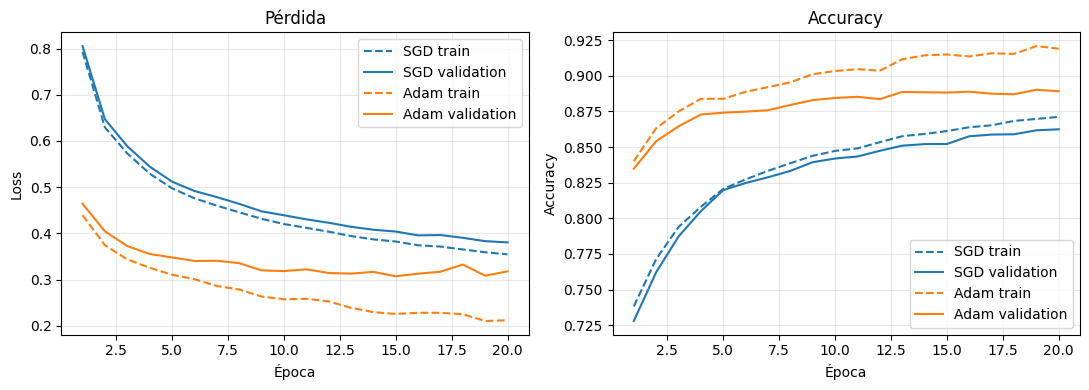

In [ ]:
# Gráficos de comparación (semilla principal): loss y accuracy, train y validation
epochs_axis = range(1, EPOCHS + 1)
colors = {'SGD': 'tab:blue', 'Adam': 'tab:orange'}

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
for name in OPTIMIZERS:
  h = results[(name, SEEDS[0])][1]
  plt.plot(epochs_axis, h['train_loss'], '--', color=colors[name], label=f'{name} train')
  plt.plot(epochs_axis, h['val_loss'], '-', color=colors[name], label=f'{name} validation')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Pérdida')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
for name in OPTIMIZERS:
  h = results[(name, SEEDS[0])][1]
  plt.plot(epochs_axis, h['train_acc'], '--', color=colors[name], label=f'{name} train')
  plt.plot(epochs_axis, h['val_acc'], '-', color=colors[name], label=f'{name} validation')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Ejecución de Test

In [ ]:
# Evaluación final sobre test
test_loss, test_acc = evaluate(best_model, test_loader, criterion)

print(f'Optimizador: {best_name}')
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')

Optimizador: Adam
Test loss: 0.3333
Test accuracy: 0.8838


In [ ]:
# Predicciones sobre todo test
best_model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        logits = best_model(images.to(device))
        all_preds.append(logits.argmax(dim=1).cpu())   # clase predicha = logit más grande
        all_labels.append(labels)

all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

# Debe coincidir con la test accuracy de arriba
print((all_preds == all_labels).mean())

0.8838


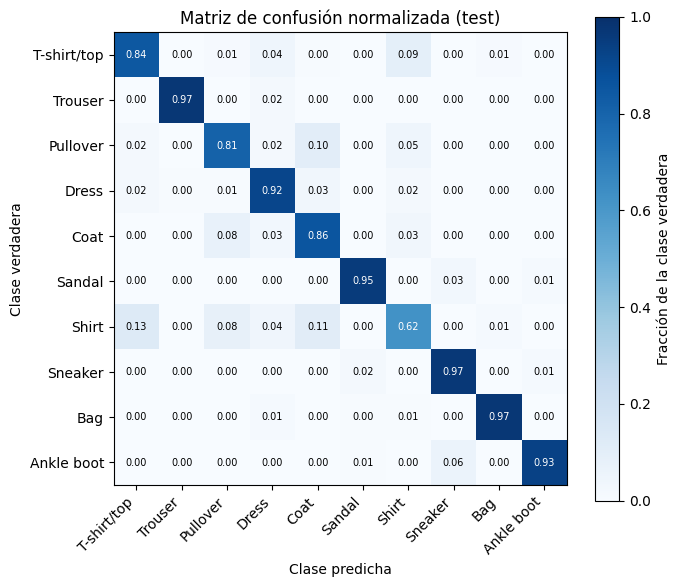

In [ ]:
# Matriz de confusión: filas = clase verdadera, columnas = clase predicha
n_classes = 10
cm = np.zeros((n_classes, n_classes), dtype=int)
for true, pred in zip(all_labels, all_preds):
    cm[true, pred] += 1

cm_norm = cm / cm.sum(axis=1, keepdims=True)

# Figura de la matriz de confusión normalizada
names = [class_names[i] for i in range(n_classes)]

plt.figure(figsize=(7, 6))
plt.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
plt.colorbar(label='Fracción de la clase verdadera')
plt.xticks(range(n_classes), names, rotation=45, ha='right')
plt.yticks(range(n_classes), names)
plt.xlabel('Clase predicha')
plt.ylabel('Clase verdadera')
plt.title('Matriz de confusión normalizada (test)')

# Valor de cada celda (texto blanco sobre las celdas oscuras)
for i in range(n_classes):
    for j in range(n_classes):
        plt.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center',
                 color='white' if cm_norm[i, j] > 0.5 else 'black', fontsize=7)

plt.tight_layout()
plt.show()

In [ ]:
# Accuracy por clase = diagonal de la matriz normalizada
per_class_acc = np.diag(cm_norm)

print('Accuracy por clase (de mayor a menor):')
for i in np.argsort(per_class_acc)[::-1]:
    print(f'  {class_names[i]:12s} {per_class_acc[i]:.3f}')

Accuracy por clase (de mayor a menor):
  Trouser      0.970
  Bag          0.969
  Sneaker      0.966
  Sandal       0.955
  Ankle boot   0.932
  Dress        0.916
  Coat         0.857
  T-shirt/top  0.845
  Pullover     0.805
  Shirt        0.623


In [ ]:
# Confusiones más frecuentes (fuera de la diagonal)
confusiones = []
for i in range(n_classes):
    for j in range(n_classes):
        if i != j:
            confusiones.append((cm_norm[i, j], i, j))

confusiones.sort(reverse=True)

print('Confusiones más frecuentes (verdadera -> predicha):')
for frac, i, j in confusiones[:5]:
    print(f'  {class_names[i]} -> {class_names[j]}: {frac:.3f} ({cm[i, j]} imágenes)')

Confusiones más frecuentes (verdadera -> predicha):
  Shirt -> T-shirt/top: 0.129 (129 imágenes)
  Shirt -> Coat: 0.112 (112 imágenes)
  Pullover -> Coat: 0.105 (105 imágenes)
  T-shirt/top -> Shirt: 0.090 (90 imágenes)
  Shirt -> Pullover: 0.080 (80 imágenes)


# Gráficos Finales

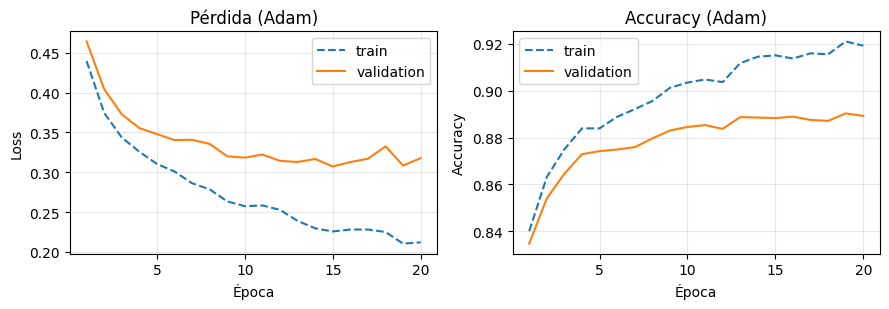

In [ ]:
# Curvas de entrenamiento del modelo elegido (dos paneles)
epochs_axis = range(1, len(best_history['train_loss']) + 1)

plt.figure(figsize=(9, 3.2))

plt.subplot(1, 2, 1)
plt.plot(epochs_axis, best_history['train_loss'], '--', label='train')
plt.plot(epochs_axis, best_history['val_loss'], '-', label='validation')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.title(f'Pérdida ({best_name})')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_axis, best_history['train_acc'], '--', label='train')
plt.plot(epochs_axis, best_history['val_acc'], '-', label='validation')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.title(f'Accuracy ({best_name})')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('curvas.png', dpi=200, bbox_inches='tight')
plt.show()

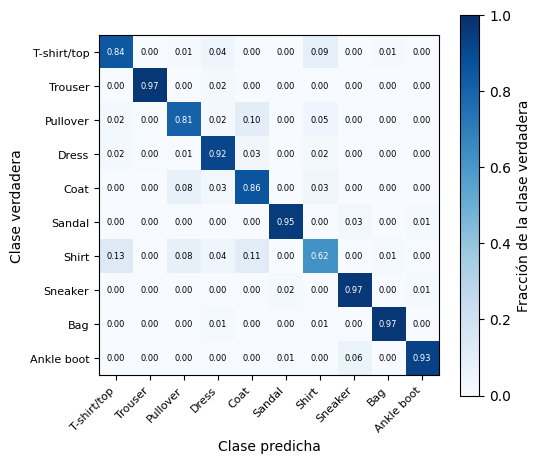

In [ ]:
# Matriz de confusión normalizada, en tamaño compacto
plt.figure(figsize=(5.5, 4.8))
plt.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
plt.colorbar(label='Fracción de la clase verdadera')
plt.xticks(range(n_classes), names, rotation=45, ha='right', fontsize=8)
plt.yticks(range(n_classes), names, fontsize=8)
plt.xlabel('Clase predicha')
plt.ylabel('Clase verdadera')

for i in range(n_classes):
    for j in range(n_classes):
        plt.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center',
                 color='white' if cm_norm[i, j] > 0.5 else 'black', fontsize=6)

plt.tight_layout()
plt.savefig('matriz_confusion.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# Números finales para el informe
print('Comparación SGD vs Adam')
for name in OPTIMIZERS:
    vl = np.array([results[(name, s)][1]['val_loss'][-1] for s in SEEDS])
    va = np.array([results[(name, s)][1]['val_acc'][-1] for s in SEEDS])
    print(f'{name} & {LRS[name]} & {vl.mean():.3f} $\\pm$ {vl.std(ddof=1):.3f} '
          f'& {va.mean():.3f} $\\pm$ {va.std(ddof=1):.3f} \\\\')

print('\nModelo elegido (semilla', SEEDS[0], ')')
print(f"Validation (última época): loss {best_history['val_loss'][-1]:.4f}, acc {best_history['val_acc'][-1]:.4f}")
print(f'Test: loss {test_loss:.4f}, acc {test_acc:.4f}')

print('\nAccuracy por clase')
for i in np.argsort(per_class_acc)[::-1]:
    print(f'{class_names[i]:12s} {per_class_acc[i]:.3f}')

Comparación SGD vs Adam
SGD & 0.01 & 0.384 $\pm$ 0.003 & 0.861 $\pm$ 0.002 \\
Adam & 0.001 & 0.317 $\pm$ 0.010 & 0.890 $\pm$ 0.002 \\

Modelo elegido (semilla 42 )
Validation (última época): loss 0.3178, acc 0.8892
Test: loss 0.3333, acc 0.8838

Accuracy por clase
Trouser      0.970
Bag          0.969
Sneaker      0.966
Sandal       0.955
Ankle boot   0.932
Dress        0.916
Coat         0.857
T-shirt/top  0.845
Pullover     0.805
Shirt        0.623
